In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
from data_pipeline import load_data, get_gacc, join_geo_data, mann_whitney_test, data_summary
from visuals import (gacc_map, gacc_fire_map, results_region_map,
                     plot_monthly_fires, plot_r_bars, human_cause_breakdown, chart_path)

In [2]:
gacc = get_gacc()
fires = join_geo_data(load_data(), gacc)
fires.shape

GACC Regions: ['Alaska', 'Eastern Area', 'Great Basin', 'Northern California', 'Northern Rockies', 'Northwest', 'Rocky Mountain', 'Southern Area', 'Southern California', 'Southwest']
Polygon Bounds: [-179.23110125   24.3963123   179.85966573   71.43978571]
querying
data read
(2661381, 15)
converting discovery date
converting contained date
calculating duration
dropping unknown fires
dropped 270796 unknown ignition fires
fire cause classifications: ['Human' 'Natural']
Dropped 714 fires outside AK + lower 48
Check for Duplicate Rows
Geo Dataset Rows: 2389871 | Input Dataset Rows: 2390071
Fires not in any GACC: 27
              fire_name  fire_year state   latitude   longitude
24100             LUCKY       2007    AZ  31.333056 -110.639444
25726             YAQUI       2007    AZ  31.333333 -110.320833
156200    SCHOOL CANYON       2003    AZ  31.333056 -110.390278
172077         MARIPOSA       2004    AZ  31.332500 -110.983056
213138        MEXICO #2       1994    AZ  31.334300 -109.7867

(2390069, 15)

In [3]:
national = mann_whitney_test(fires)
national

n_human                    2033676
n_natural                   356393
median_human                   1.0
median_natural                 0.2
U                   420263726941.0
p_value                        0.0
r_rb                      0.159687
prob_superiority          0.579844
conclusion            Human Larger
dtype: object

In [4]:
regional = pd.DataFrame(
    {name: mann_whitney_test(g) for name, g in fires.groupby("gaccname")}
).T
regional[["n_human", "n_natural", "median_human", "median_natural", "r_rb", "conclusion"]]

,n_human,n_natural,median_human,median_natural,r_rb,conclusion
Alaska,10572,5856,0.1,25.275,-0.750256,Natural Larger
Eastern Area,422340,15325,0.5,0.25,0.134707,Human Larger
Great Basin,39209,54221,0.3,0.1,0.15346,Human Larger
Northern California,79781,20322,0.25,0.1,0.144029,Human Larger
Northern Rockies,58883,40341,0.5,0.2,0.089675,No meaningful difference
Northwest,73403,50268,0.1,0.1,-0.040748,No meaningful difference
Rocky Mountain,146445,43316,0.1,0.1,-0.080217,No meaningful difference
Southern Area,1013064,62018,1.5,2.3,-0.127073,Natural Larger
Southern California,109128,10684,0.25,0.1,0.138685,Human Larger
Southwest,80851,54042,0.2,0.1,0.029385,No meaningful difference


In [5]:
folder_name = "national_all_fires"

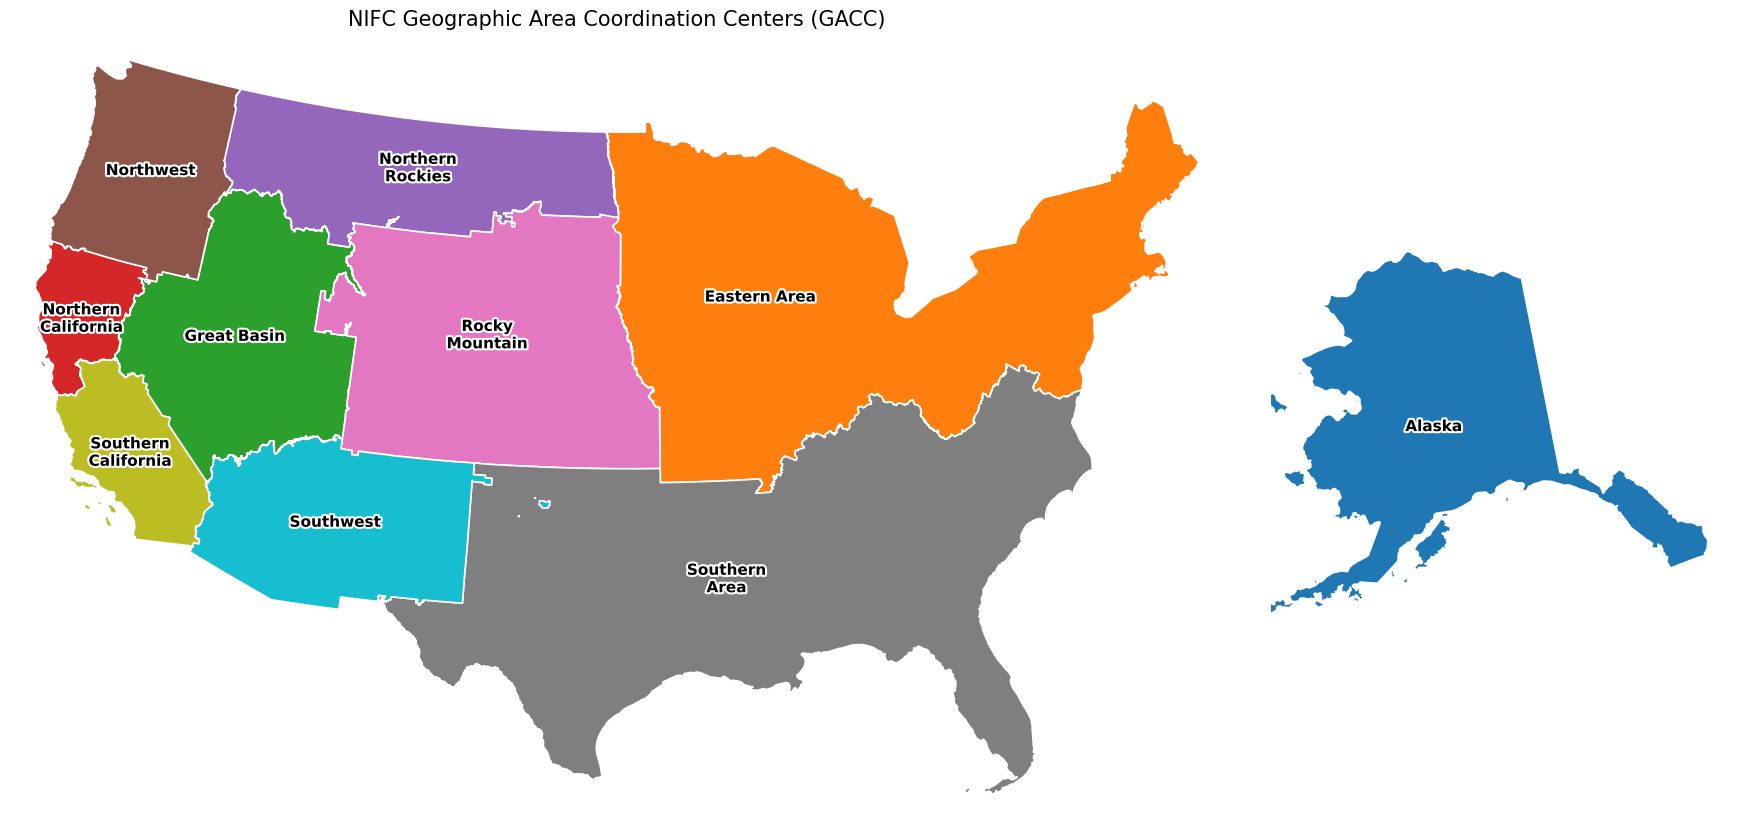

In [6]:
gacc_map(gacc, save_path=chart_path(folder_name, f"{folder_name}_gacc_regions.png"))

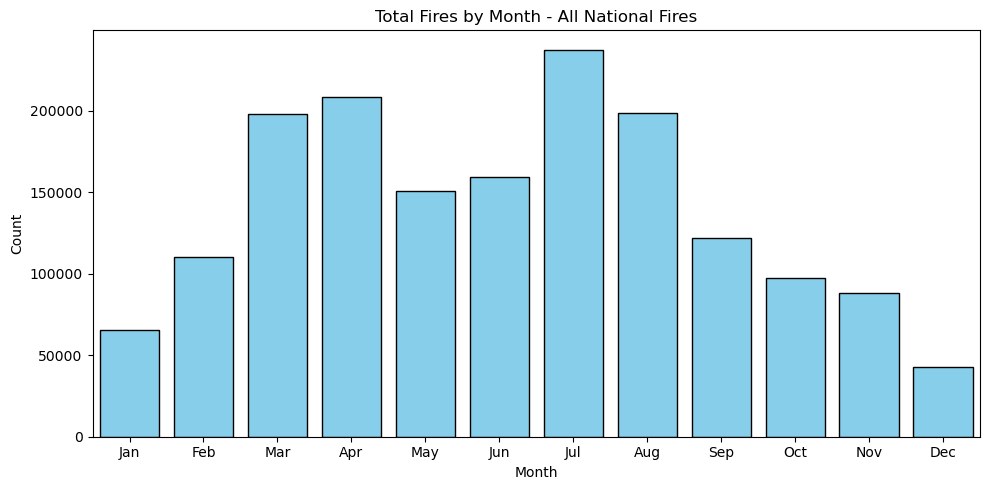

In [7]:
plot_monthly_fires(fires, "All National Fires", save_path=chart_path(folder_name, f"{folder_name}_monthly_fires.png"))


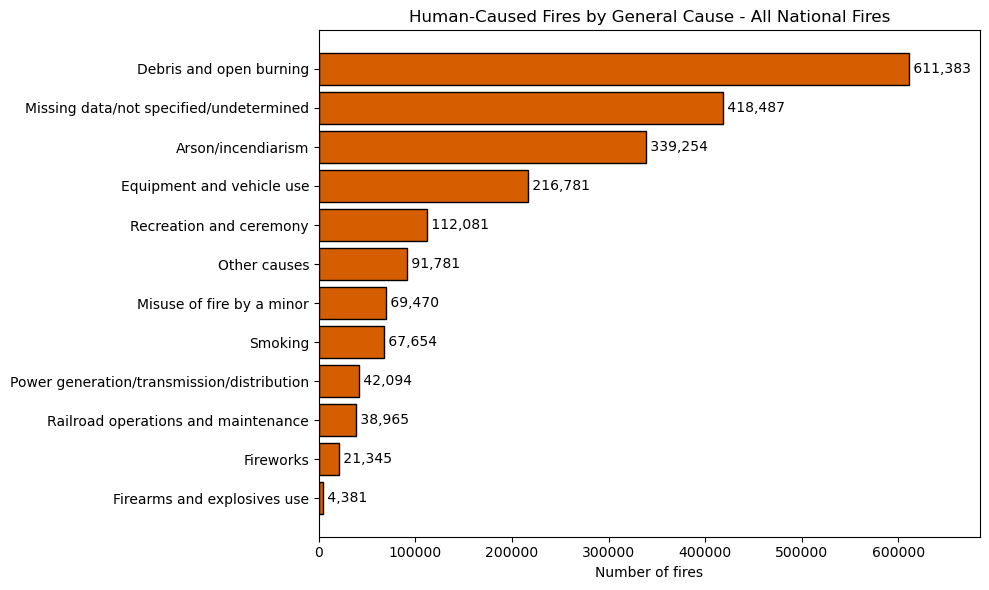

In [8]:
human_cause_breakdown(fires, "All National Fires", save_path=chart_path("national", "human_causes.png"))

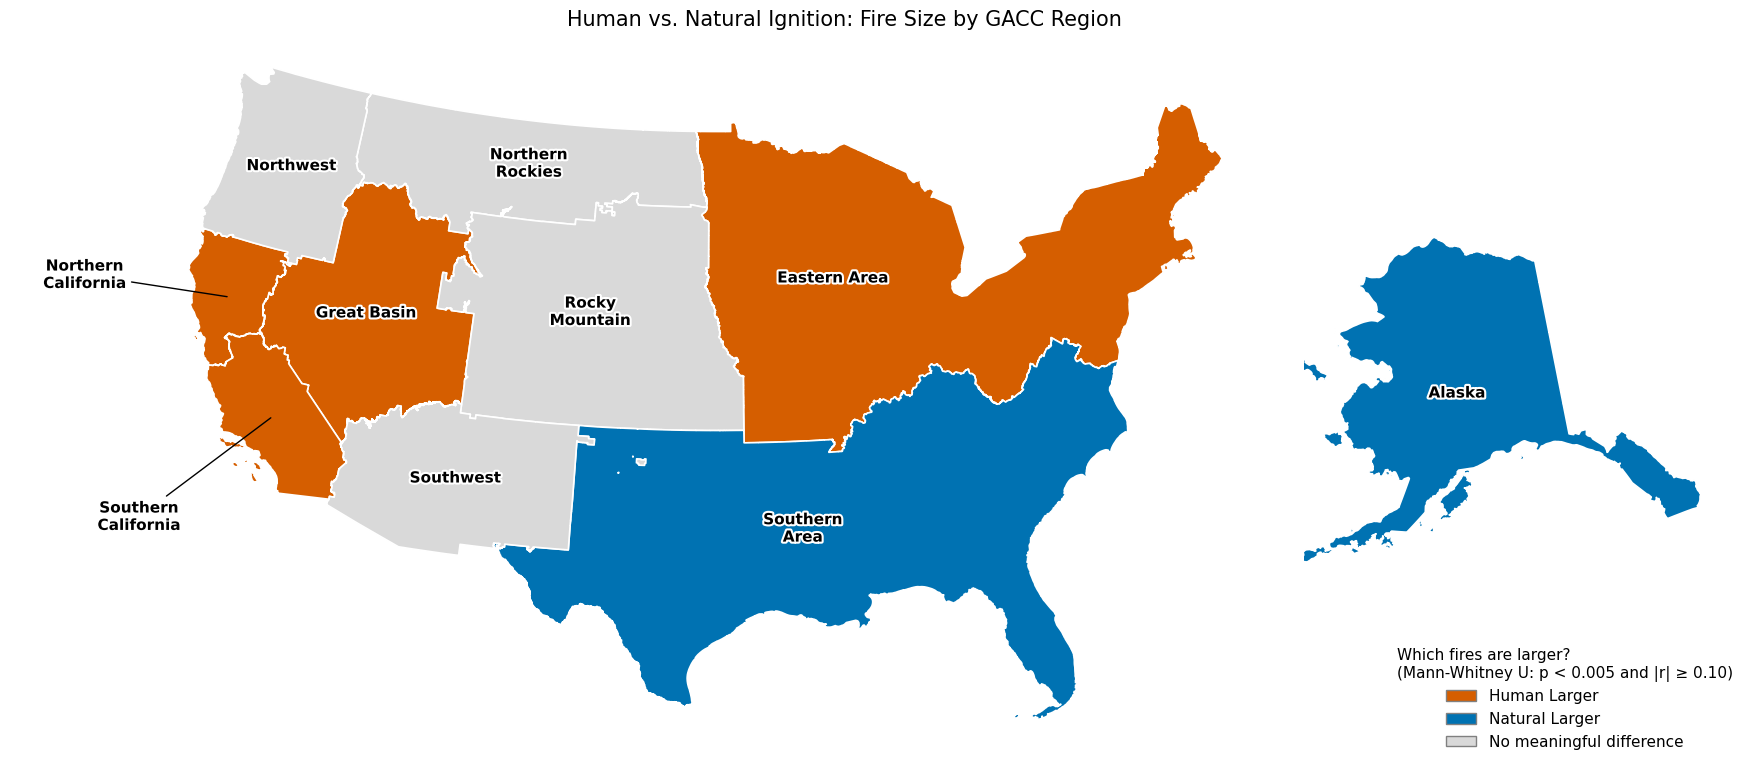

In [9]:
results_region_map(
    regional,
    gacc=gacc,
    legend_title="Which fires are larger?\n(Mann-Whitney U: p < 0.005 and |r| ≥ 0.10)",
    title="Human vs. Natural Ignition: Fire Size by GACC Region",
    save_path=chart_path(folder_name, f"{folder_name}_region_map.png"),
)



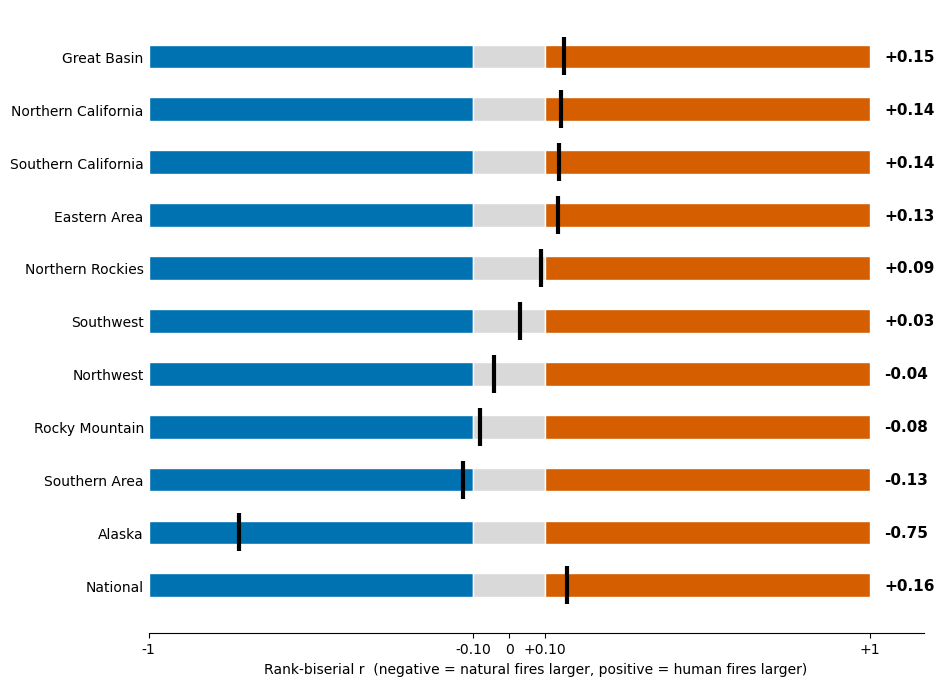

In [13]:
plot_r_bars(regional, national_r=float(national["r_rb"]),
            save_path=chart_path(folder_name, f"{folder_name}_all_r_bars.png"))

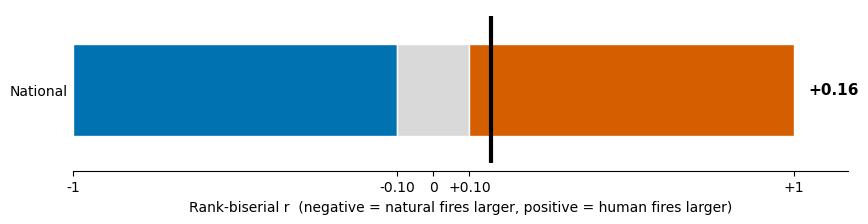

In [11]:
national_df = pd.DataFrame([national], index=["National"])

plot_r_bars(national_df, save_path=chart_path(folder_name, f"{folder_name}_r_bars.png"))

Scaling fires
Sorting fires
Creating fires map
Saved GACC fires map to /home/jarom/projects/wgu_wildfire/charts/national_all_fires/national_all_fires_gacc_fires.png


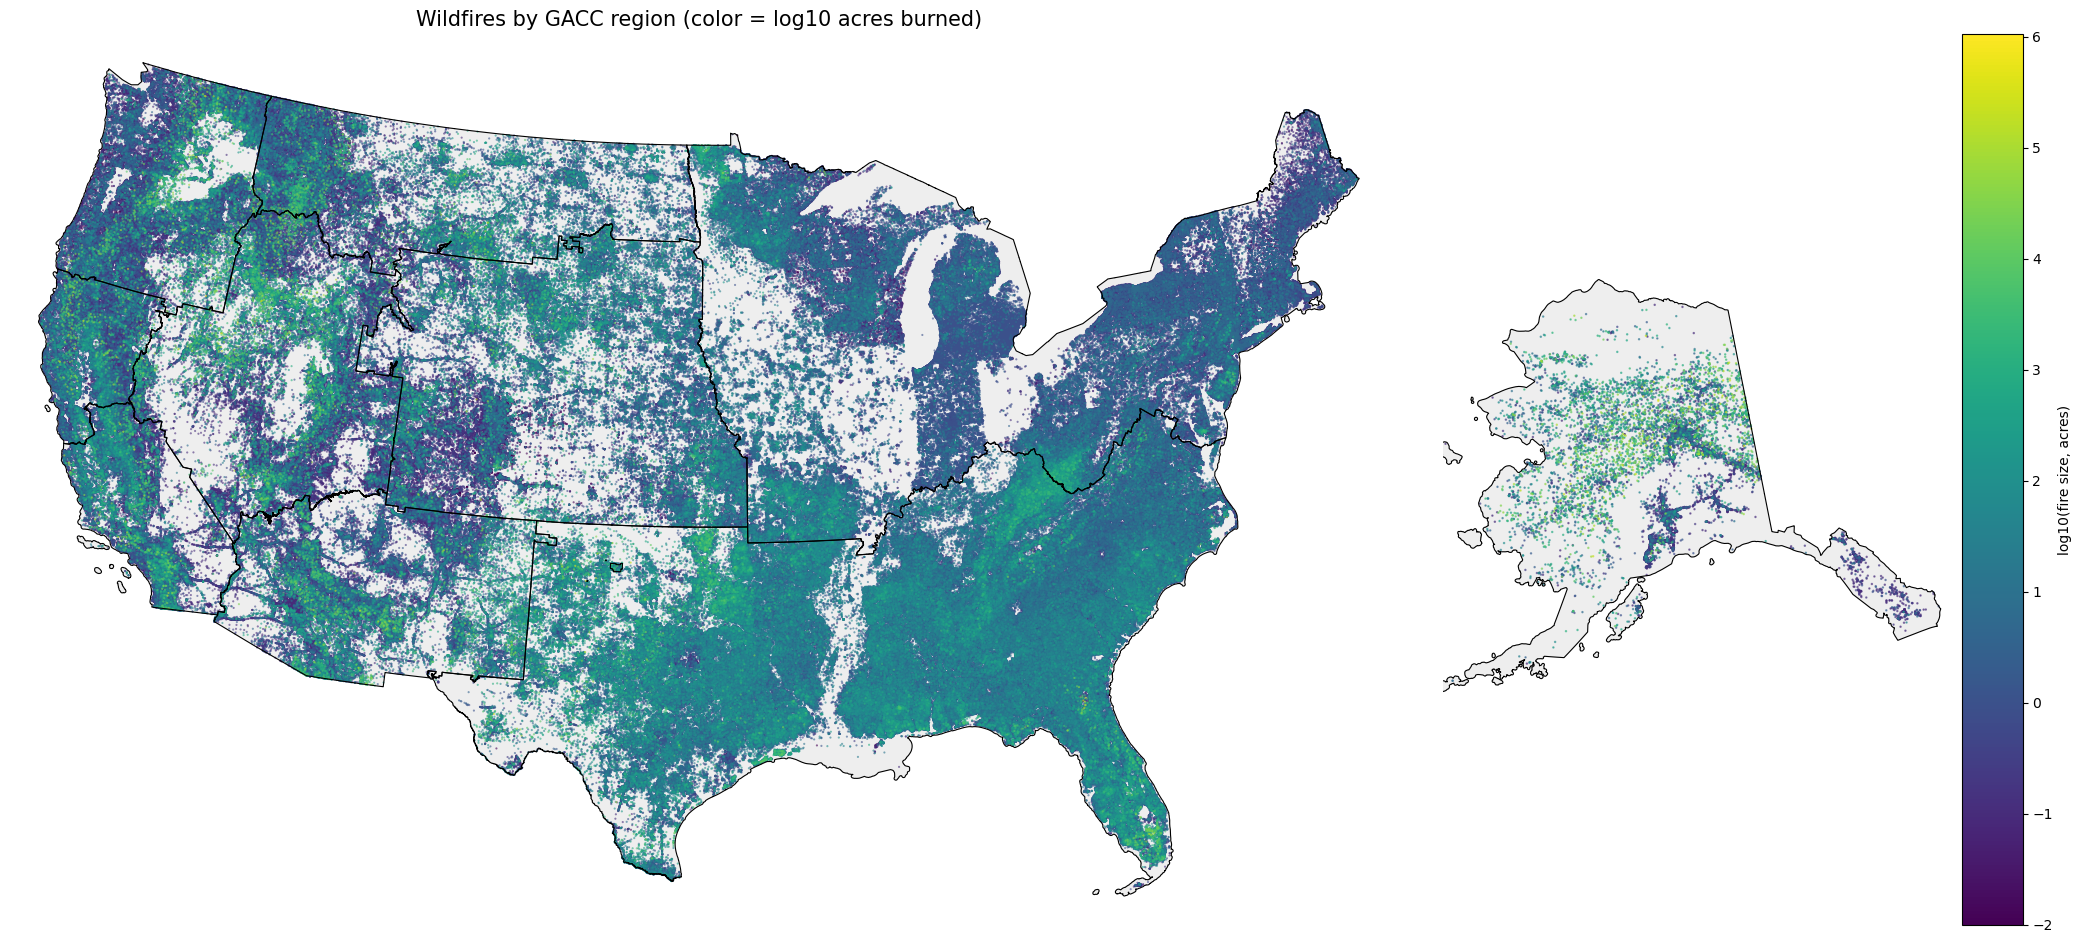

In [12]:
gacc_fire_map(fires, gacc, save_path=chart_path(folder_name, f"{folder_name}_gacc_fires.png"))